In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/taylor_album_songs.csv")
df.shape

(194, 29)

In [3]:
df.columns.tolist()

['album_name',
 'ep',
 'album_release',
 'track_number',
 'track_name',
 'artist',
 'featuring',
 'bonus_track',
 'promotional_release',
 'single_release',
 'track_release',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'duration_ms',
 'explicit',
 'key_name',
 'mode_name',
 'key_mode',
 'lyrics']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   album_name           194 non-null    str    
 1   ep                   194 non-null    bool   
 2   album_release        194 non-null    str    
 3   track_number         194 non-null    int64  
 4   track_name           194 non-null    str    
 5   artist               191 non-null    str    
 6   featuring            16 non-null     str    
 7   bonus_track          194 non-null    bool   
 8   promotional_release  18 non-null     str    
 9   single_release       36 non-null     str    
 10  track_release        194 non-null    str    
 11  danceability         191 non-null    float64
 12  energy               191 non-null    float64
 13  key                  191 non-null    float64
 14  loudness             191 non-null    float64
 15  mode                 191 non-null    float64
 16  s

In [5]:
df.head(3)

,album_name,ep,album_release,track_number,track_name,artist,featuring,bonus_track,promotional_release,single_release,...,liveness,valence,tempo,time_signature,duration_ms,explicit,key_name,mode_name,key_mode,lyrics
0,Taylor Swift,False,2006-10-24,1,Tim McGraw,Taylor Swift,NaN,False,NaN,2006-06-19,...,0.1210,0.425,76.009,4.0,232107.0,False,C,major,C major,NaN
1,Taylor Swift,False,2006-10-24,2,Picture To Burn,Taylor Swift,NaN,False,NaN,2008-02-03,...,0.0962,0.821,105.586,4.0,173067.0,False,G,major,G major,NaN
2,Taylor Swift,False,2006-10-24,3,Teardrops On My Guitar,Taylor Swift,NaN,False,NaN,2007-02-19,...,0.1190,0.289,99.953,4.0,203040.0,False,A#,major,A# major,NaN


In [6]:
display(df[df["danceability"].isna()][["album_name", "track_name", "artist"]])
display(df.describe().T.round(2))
display(df.groupby("album_name")[["valence", "energy", "acousticness"]].mean().round(2))

,album_name,track_name,artist
191,Midnights,Hits Different,NaN
192,Midnights,"You're On Your Own, Kid (Strings Remix)",NaN
193,Midnights,Sweet Nothing (Piano Remix),NaN


,count,mean,std,min,25%,50%,75%,max
track_number,194.0,10.71,6.60,1.00,5.00,10.00,15.00,30.00
danceability,191.0,0.58,0.12,0.29,0.51,0.59,0.65,0.90
energy,191.0,0.57,0.18,0.13,0.45,0.58,0.72,0.95
key,191.0,4.69,3.34,0.00,2.00,5.00,7.00,11.00
loudness,191.0,-7.52,2.78,-15.43,-9.33,-6.94,-5.61,-2.10
mode,191.0,0.91,0.29,0.00,1.00,1.00,1.00,1.00
speechiness,191.0,0.06,0.06,0.02,0.03,0.04,0.06,0.52
acousticness,191.0,0.32,0.33,0.00,0.03,0.16,0.66,0.97
instrumentalness,191.0,0.00,0.03,0.00,0.00,0.00,0.00,0.35
liveness,191.0,0.14,0.08,0.04,0.09,0.12,0.15,0.59


,valence,energy,acousticness
album_name,,,
1989,0.45,0.70,0.14
Fearless (Taylor's Version),0.42,0.64,0.21
Lover,0.48,0.55,0.33
Midnights,0.28,0.45,0.41
Red (Taylor's Version),0.42,0.59,0.18
Speak Now,0.41,0.67,0.20
Taylor Swift,0.43,0.66,0.18
evermore,0.43,0.49,0.79
folklore,0.36,0.42,0.72


In [7]:
df = df.dropna(subset=["danceability"]).copy()
df = df.drop(columns=["lyrics"])
df["album_release"] = pd.to_datetime(df["album_release"])
df["track_release"] = pd.to_datetime(df["track_release"])
df["explicit"] = df["explicit"].astype(bool)
df.shape

(191, 28)

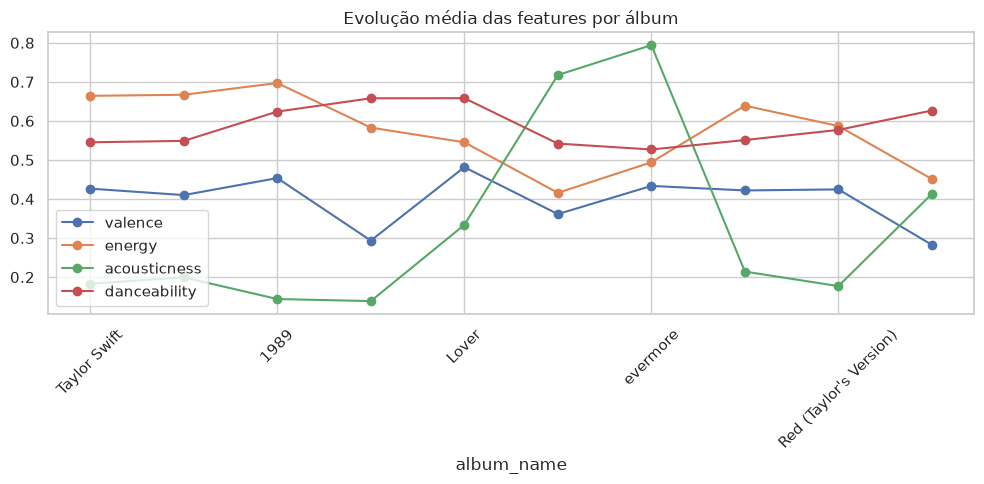

In [8]:
ordem = df.groupby("album_name")["album_release"].min().sort_values().index
medias = (df.groupby("album_name")[["valence", "energy", "acousticness", "danceability"]]
            .mean().loc[ordem])
medias.plot(marker="o", figsize=(10, 5), rot=45)
plt.title("Evolução média das features por álbum")
plt.tight_layout()
plt.show()